# 05 - Statistical Analysis

## 1. Setup and the modelling table

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, ndimage
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
import rasterio
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGDIR, TABDIR = ROOT / "data", ROOT / "figures", ROOT / "tables"
FIGDIR.mkdir(exist_ok=True); TABDIR.mkdir(exist_ok=True)
RASTER = DATA / "rasters" / "classmap_fullcoast_30m.tif"

SEED, BLOCK_DEG, TARGET = 2026, 0.25, "now_nbr"
PIXEL_HA = 2522.33 / 29453
RF_ARGS = dict(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
               n_jobs=-1, random_state=SEED)
OUT = {}                      # everything the manuscript quotes goes in here

BASE = ["pre_nbr", "magnitude", "dist_to_survivor", "dist_to_edge",
        "patch_area", "mangrove_frac_1km", "climate_shift", "rmse"]
d = pd.read_csv(DATA / "pixels_with_covariates.csv")
extra = []
for f in sorted((DATA / "covariates").glob("*.csv")):
    c = pd.read_csv(f)
    if not {"longitude", "latitude", "value"}.issubset(c.columns):
        continue
    _, i = cKDTree(c[["longitude", "latitude"]].values).query(
        d[["longitude", "latitude"]].values, k=1)
    d[f.stem] = c.value.values[i]; extra.append(f.stem)
COVARS = BASE + extra
CLIM = [c for c in ("rain_2015_mm", "rain_recovery_mm", "tmax_2015_C",
                    "tmax_recovery_C", "tmin_recovery_C") if c in COVARS]
d = d.dropna(subset=COVARS + [TARGET]).reset_index(drop=True)

blk = (np.floor(d.longitude / BLOCK_DEG).astype(int).astype(str) + "_" +
       np.floor(d.latitude / BLOCK_DEG).astype(int).astype(str)).values
codes, inv = np.unique(blk, return_inverse=True)
members = [np.flatnonzero(inv == k) for k in range(len(codes))]
NB = len(codes)
print(f"{len(d):,} dieback pixels, {len(COVARS)} predictors, {NB} blocks of {BLOCK_DEG} deg")
print("predictors:", COVARS)

29,453 dieback pixels, 14 predictors, 52 blocks of 0.25 deg
predictors: ['pre_nbr', 'magnitude', 'dist_to_survivor', 'dist_to_edge', 'patch_area', 'mangrove_frac_1km', 'climate_shift', 'rmse', 'dist_to_channel_m', 'rain_2015_mm', 'rain_recovery_mm', 'tmax_2015_C', 'tmax_recovery_C', 'tmin_recovery_C']


## 2. Variogram - why 27 km blocks?

Everything below treats 0.25° (~27 km) blocks as roughly independent. This
checks that choice. For pairs of pixels at increasing distance apart, it measures
how different their recovery is, as a percentage of how different two random
pixels are. Where the curve levels off is where pixels stop resembling each other.

In [2]:
rng = np.random.default_rng(SEED)
s = rng.choice(len(d), 3000, replace=False)
lat0 = np.radians(d.latitude.median())
x = d.longitude.values[s] * 111320 * np.cos(lat0)
y = d.latitude.values[s] * 110540
v = np.clip(d.recovery_ratio_adj.values[s], 0, 2)
iu = np.triu_indices(len(s), 1)
h = np.hypot(x[iu[0]] - x[iu[1]], y[iu[0]] - y[iu[1]]) / 1000
g = 0.5 * (v[iu[0]] - v[iu[1]]) ** 2
sill = v.var()
edges = [0, 1, 2, 5, 10, 15, 20, 27, 35, 50, 75, 100, 150, 200, 300, 500, 700]
vg = []
for a, b in zip(edges[:-1], edges[1:]):
    m = (h >= a) & (h < b)
    if m.sum() > 30:
        vg.append({"from_km": a, "to_km": b, "mid_km": (a + b) / 2,
                   "pct_of_sill": 100 * g[m].mean() / sill, "pairs": int(m.sum())})
vg = pd.DataFrame(vg)
print(vg[["from_km", "to_km", "pct_of_sill", "pairs"]].round(0).to_string(index=False))
vg.to_csv(TABDIR / "tableS1_variogram.csv", index=False)
OUT["variogram"] = vg.to_dict("records")

 from_km  to_km  pct_of_sill  pairs
       0      1         64.0  41497
       1      2         70.0  30381
       2      5         72.0  62824
       5     10         73.0  84696
      10     15         77.0  80954
      15     20         79.0  76271
      20     27         87.0 105919
      27     35         82.0 127297
      35     50         83.0 255571
      50     75         81.0 379702
      75    100         85.0 359772
     100    150         95.0 596437
     150    200        104.0 444241
     200    300        102.0 379381
     300    500        122.0 611311
     500    700        120.0 862246


## 3. Uncertainty ranges on the resilience numbers

**Spatial block bootstrap.** Pick 52 blocks at random (repeats allowed),
recalculate each number, do it 2,000 times. The middle 95% of the answers is
the range. Blocks, not single pixels, because neighbouring pixels are near-copies.

In [3]:
N_BOOT = 2000
never = d.years_to_recovery.isna().values
STATS = {"never_recovered_pct": never,
         "secondary_decline_pct": (~never) & (d.recovery_ratio < 0.8).values,
         "adj_below_threshold_pct": (d.recovery_ratio_adj < 0.8).values}
CONT = {"median_recovery_ratio_adj": d.recovery_ratio_adj.values,
        "median_recovery_rate_adj": d.recovery_rate_adj.values,
        "median_magnitude": d.magnitude.values}
west = (d.longitude < 138.5).values
adj = d.recovery_ratio_adj.values
keys = list(STATS) + list(CONT) + ["west_median", "east_median", "ew_diff"]
boot = {k: np.empty(N_BOOT) for k in keys}
rng = np.random.default_rng(SEED)
for b in range(N_BOOT):
    idx = np.concatenate([members[k] for k in rng.integers(0, NB, NB)])
    for k, a in STATS.items(): boot[k][b] = a[idx].mean() * 100
    for k, a in CONT.items():  boot[k][b] = np.median(a[idx])
    w = west[idx]
    boot["west_median"][b] = np.median(adj[idx][w]) if w.any() else np.nan
    boot["east_median"][b] = np.median(adj[idx][~w]) if (~w).any() else np.nan
    boot["ew_diff"][b] = boot["west_median"][b] - boot["east_median"][b]

point = {**{k: a.mean() * 100 for k, a in STATS.items()},
         **{k: float(np.median(a)) for k, a in CONT.items()},
         "west_median": float(np.median(adj[west])),
         "east_median": float(np.median(adj[~west]))}
point["ew_diff"] = point["west_median"] - point["east_median"]
res = {}
print(f"{'measure':<28}{'estimate':>10}   95% range")
for k in keys:
    lo, hi = np.nanpercentile(boot[k], [2.5, 97.5])
    res[k] = {"estimate": float(point[k]), "lo": float(lo), "hi": float(hi)}
    print(f"{k:<28}{point[k]:>10.3f}   [{lo:.3f}, {hi:.3f}]")
for k in STATS:
    f = len(d) * PIXEL_HA / 100
    r = res[k]
    print(f"   {k.replace('_pct','')} = {r['estimate']*f:,.0f} ha [{r['lo']*f:,.0f}, {r['hi']*f:,.0f}]")
    res[k.replace("_pct", "_ha")] = {kk: vv * f for kk, vv in r.items()}
OUT["resilience"] = res

measure                       estimate   95% range
never_recovered_pct             26.714   [18.249, 38.640]
secondary_decline_pct            9.609   [7.399, 11.871]
adj_below_threshold_pct         44.372   [33.427, 58.472]
median_recovery_ratio_adj        0.852   [0.729, 0.964]
median_recovery_rate_adj         0.034   [0.030, 0.039]
median_magnitude                 0.338   [0.307, 0.376]
west_median                      0.592   [0.501, 0.694]
east_median                      0.929   [0.833, 1.042]
ew_diff                         -0.338   [-0.480, -0.192]
   never_recovered = 674 ha [460, 975]
   secondary_decline = 242 ha [187, 299]
   adj_below_threshold = 1,119 ha [843, 1,475]


## 4. Model Reliability?

**Repeated blocked cross-validation.** Hide whole 27 km blocks, predict them,
score it (R²). Which blocks get hidden together changes the score a lot, so the
split is randomised and repeated 5 times; the average is reported.

**Ablation.** Take a group of predictors out and re-score. A big drop means the
group mattered. **Random folds** are also run once, to show how much ignoring the
neighbour problem would inflate the score.

In [4]:
N_REP, N_FOLD, N_TREE = 5, 5, 200
y = d[TARGET].values
SETS = {"all predictors": COVARS,
        "intrinsic only": BASE,
        "without climate": [c for c in COVARS if c not in CLIM],
        "projectable set": [c for c in COVARS if c not in ("magnitude", "dist_to_survivor", "patch_area")],
        "without rmse": [c for c in COVARS if c != "rmse"],
        "without pre_nbr": [c for c in COVARS if c != "pre_nbr"],
        "environment only": [c for c in COVARS if c not in ("pre_nbr", "rmse", "magnitude")]}

def rf_small():
    return RandomForestRegressor(**{**RF_ARGS, "n_estimators": N_TREE})

cv = {}
t0 = time.time()
for name, cs in SETS.items():
    X = d[cs].values; reps, folds = [], []
    for r in range(N_REP):
        fold = (np.random.default_rng(SEED + 100 * r).permutation(NB) % N_FOLD)[inv]
        sc = [rf_small().fit(X[fold != k], y[fold != k]).score(X[fold == k], y[fold == k])
              for k in range(N_FOLD)]
        reps.append(np.mean(sc)); folds += sc
    cv[name] = {"r2_mean": float(np.mean(reps)), "r2_sd": float(np.std(reps)),
                "fold_min": float(min(folds)), "fold_max": float(max(folds)),
                "n_predictors": len(cs)}
    print(f"{name:<18} R2 {np.mean(reps):6.3f} +/- {np.std(reps):.3f}   "
          f"folds [{min(folds):+.2f}, {max(folds):+.2f}]   ({time.time()-t0:.0f}s)")
base = cv["all predictors"]["r2_mean"]
for k in cv: cv[k]["delta"] = cv[k]["r2_mean"] - base

X = d[COVARS].values
rnd = [rf_small().fit(X[tr], y[tr]).score(X[te], y[te])
       for r in range(N_REP)
       for tr, te in KFold(N_FOLD, shuffle=True, random_state=SEED + r).split(X)]
print(f"\nrandom folds       R2 {np.mean(rnd):6.3f}   -> inflation {np.mean(rnd)-base:+.3f}")
OUT["cv"] = {"sets": cv, "r2_random": float(np.mean(rnd)),
             "inflation": float(np.mean(rnd) - base)}
pd.DataFrame(cv).T.round(3).to_csv(TABDIR / "table4c_ablation_repeated.csv")

all predictors     R2  0.365 +/- 0.020   folds [+0.22, +0.49]   (61s)
intrinsic only     R2  0.276 +/- 0.034   folds [+0.02, +0.44]   (114s)
without climate    R2  0.279 +/- 0.031   folds [+0.08, +0.44]   (189s)
projectable set    R2  0.349 +/- 0.015   folds [+0.17, +0.47]   (252s)
without rmse       R2  0.339 +/- 0.017   folds [+0.21, +0.45]   (310s)
without pre_nbr    R2  0.189 +/- 0.030   folds [-0.05, +0.36]   (369s)
environment only   R2  0.122 +/- 0.030   folds [-0.10, +0.29]   (418s)

random folds       R2  0.759   -> inflation +0.394


## 5. Shape of each effect, and rainfall test

**ALE (accumulated local effects).** How much the prediction changes as one
predictor goes from its lowest to its highest value. The "range" is the size of
that effect in NBR units.

**Dutilleul modified t-test.** Is the correlation between recovery and each
climate variable real once account for neighbours? It estimates the number
of *effectively independent* places (M_eff) and tests with that instead of
29,453.

In [5]:
rf = RandomForestRegressor(**RF_ARGS).fit(d[COVARS].values, y)
X = d[COVARS].values

def ale_1d(model, Xm, j, n_bins=25):
    q = np.unique(np.quantile(Xm[:, j], np.linspace(0, 1, n_bins + 1)))
    k = np.clip(np.searchsorted(q, Xm[:, j], side="left"), 1, len(q) - 1)
    lo, hi = Xm.copy(), Xm.copy(); lo[:, j], hi[:, j] = q[k - 1], q[k]
    md_ = pd.Series(model.predict(hi) - model.predict(lo)).groupby(k).mean()
    acc = np.zeros(len(q))
    acc[1:] = md_.reindex(range(1, len(q))).fillna(0).cumsum().values
    w = pd.Series(k).value_counts().reindex(range(1, len(q))).fillna(0).values
    acc -= np.sum(w * (acc[1:] + acc[:-1]) / 2) / w.sum()
    return (q[:-1] + q[1:]) / 2, acc[1:]

ALE = {}
for c in ["pre_nbr", "magnitude", "climate_shift", "rain_2015_mm",
          "rain_recovery_mm", "dist_to_channel_m"]:
    if c in COVARS:
        xs, ys = ale_1d(rf, X, COVARS.index(c))
        ALE[c] = {"x": xs.tolist(), "ale": ys.tolist(), "range": float(ys.max() - ys.min())}
        print(f"ALE {c:<20} effect range {ALE[c]['range']:.3f} NBR")
OUT["ale"] = ALE

def modified_ttest(a, b, lon, lat, m=2500, n_class=25, seed=0):
    r_ = np.random.default_rng(seed)
    s = r_.choice(len(a), min(m, len(a)), replace=False)
    xa, xb = a[s], b[s]
    la = np.radians(np.median(lat))
    px, py = lon[s] * 111320 * np.cos(la), lat[s] * 110540
    n = len(s); iu = np.triu_indices(n, 1)
    dist = np.hypot(px[iu[0]] - px[iu[1]], py[iu[0]] - py[iu[1]])
    edges = np.unique(np.quantile(dist, np.linspace(0, 1, n_class + 1)))
    cls = np.clip(np.searchsorted(edges, dist, side="right") - 1, 0, len(edges) - 2)
    ca, cb = xa - xa.mean(), xb - xb.mean()
    pa, pb = ca[iu[0]] * ca[iu[1]], cb[iu[0]] * cb[iu[1]]
    va, vb = (ca ** 2).mean(), (cb ** 2).mean()
    inv_m = 1.0 / n
    for k in range(len(edges) - 1):
        sel = cls == k
        if sel.any():
            inv_m += 2.0 * sel.sum() * (pa[sel].mean() / va) * (pb[sel].mean() / vb) / n ** 2
    M = float(np.clip(1.0 / inv_m, 3, n))
    r = np.corrcoef(xa, xb)[0, 1]
    t = r * np.sqrt((M - 2) / max(1 - r ** 2, 1e-12))
    return r, M, 2 * stats.t.sf(abs(t), M - 2)

MT = {}
print()
for b in [c for c in ("rain_recovery_mm", "rain_2015_mm", "dist_to_channel_m",
                      "tmax_recovery_C") if c in COVARS]:
    reps = [modified_ttest(d.recovery_ratio_adj.values, d[b].values,
                           d.longitude.values, d.latitude.values, seed=SEED + i)
            for i in range(10)]
    M = np.array([z[1] for z in reps]); p = np.array([z[2] for z in reps])
    r_full = float(np.corrcoef(d.recovery_ratio_adj, d[b])[0, 1])
    MT[b] = {"r": r_full, "M_eff": float(M.mean()), "M_sd": float(M.std()),
             "p_median": float(np.median(p)), "p_worst": float(p.max())}
    print(f"Dutilleul {b:<18} r = {r_full:+.3f}  M_eff = {M.mean():5.1f} "
          f"(not {len(d):,})  p = {np.median(p):.3f}")
OUT["dutilleul"] = MT

ALE pre_nbr              effect range 0.197 NBR
ALE magnitude            effect range 0.052 NBR
ALE climate_shift        effect range 0.067 NBR
ALE rain_2015_mm         effect range 0.025 NBR
ALE rain_recovery_mm     effect range 0.050 NBR
ALE dist_to_channel_m    effect range 0.058 NBR

Dutilleul rain_recovery_mm   r = +0.246  M_eff =  32.0 (not 29,453)  p = 0.189
Dutilleul rain_2015_mm       r = -0.036  M_eff =  36.8 (not 29,453)  p = 0.817
Dutilleul dist_to_channel_m  r = +0.151  M_eff =  80.9 (not 29,453)  p = 0.186
Dutilleul tmax_recovery_C    r = -0.376  M_eff =  13.8 (not 29,453)  p = 0.202


## 6. future map reliability

The future map predicts for 765,138 healthy pixels using a model trained on
29,453 that died. Where a healthy pixel looks unlike anything the model learned
from, its prediction is a guess. This measures that "unlikeness" (the
dissimilarity index, DI) and draws a threshold (Meyer & Pebesma 2021).

In [6]:
with rasterio.open(RASTER) as src:
    r_, c_ = rasterio.transform.rowcol(src.transform, d.longitude.values, d.latitude.values)
    r_ = np.clip(np.asarray(r_), 0, src.height - 1); c_ = np.clip(np.asarray(c_), 0, src.width - 1)
    samp = np.array([v[0] for v in src.sample(zip(d.longitude.values[:2000], d.latitude.values[:2000]))])
    on_dieback = float((samp == 2).mean())
    res_m = abs(src.transform.a) * 111320
print(f"raster resolution ~{res_m:.0f} m; {on_dieback:.1%} of dieback pixels land on class 2")
REAL_RASTER = on_dieback > 0.5 and res_m < 40
GEOM = ["dist_to_edge", "mangrove_frac_1km"]
DROP = ["magnitude", "dist_to_survivor", "patch_area"] + ([] if REAL_RASTER else GEOM)
PROJ = [c for c in COVARS if c not in DROP]
print("real 30 m raster:", REAL_RASTER, "-> projection predictors:", PROJ)
OUT["aoa_used_real_raster"] = REAL_RASTER

raster resolution ~30 m; 100.0% of dieback pixels land on class 2
real 30 m raster: True -> projection predictors: ['pre_nbr', 'dist_to_edge', 'mangrove_frac_1km', 'climate_shift', 'rmse', 'dist_to_channel_m', 'rain_2015_mm', 'rain_recovery_mm', 'tmax_2015_C', 'tmax_recovery_C', 'tmin_recovery_C']


In [7]:
Xp = d[PROJ].values
fold = (np.random.default_rng(SEED).permutation(NB) % 5)[inv]
imp, r2 = np.zeros((5, len(PROJ))), []
rng = np.random.default_rng(SEED)
for k in range(5):
    m_ = RandomForestRegressor(**RF_ARGS).fit(Xp[fold != k], y[fold != k])
    r2.append(m_.score(Xp[fold == k], y[fold == k]))
    sub = rng.choice(np.flatnonzero(fold == k), min(6000, (fold == k).sum()), replace=False)
    imp[k] = permutation_importance(m_, Xp[sub], y[sub], n_repeats=5,
                                    random_state=SEED, n_jobs=-1).importances_mean
w = np.clip(imp.mean(axis=0), 0, None); w = w / w.sum()
print(f"projection model, blocked R2 {np.mean(r2):.3f}")
for c, v in sorted(zip(PROJ, w), key=lambda t: -t[1]): print(f"  weight {c:<20}{v:.3f}")
rf_p = RandomForestRegressor(**RF_ARGS).fit(Xp, y)

un = pd.read_csv(DATA / "undisturbed_census.csv").replace(-9999, np.nan)
if REAL_RASTER:
    with rasterio.open(RASTER) as src:
        tr_, H, W = src.transform, src.height, src.width; res_deg = abs(tr_.a)
        mang, bnd = [], []
        for _, win in src.block_windows(1):
            r0, c0 = int(win.row_off), int(win.col_off); a = src.read(1, window=win)
            if not a.any(): continue
            m = a > 0; e = m & ~ndimage.binary_erosion(m, np.ones((3, 3), bool))
            for mask, store in ((m, mang), (e, bnd)):
                rr, cc = np.nonzero(mask)
                if len(rr): store.append(np.column_stack([rr + r0, cc + c0]).astype(np.int32))
    mang, bnd = np.vstack(mang), np.vstack(bnd)
    rr, cc = rasterio.transform.rowcol(tr_, un.longitude.values, un.latitude.values)
    MX = res_deg * 111320 * np.cos(np.radians(d.latitude.median())); MY = res_deg * 110540
    to_m = lambda rc: np.column_stack([rc[:, 1] * MX, rc[:, 0] * MY])
    P = to_m(np.column_stack([np.clip(rr, 0, H - 1), np.clip(cc, 0, W - 1)]))
    un["dist_to_edge"] = cKDTree(to_m(bnd)).query(P, k=1)[0]
    n_in = cKDTree(to_m(mang)).query_ball_point(P, r=500.0, return_length=True)
    un["mangrove_frac_1km"] = np.clip(n_in / (np.pi * 500.0 ** 2 / (MX * MY)), 0, 1)
    # edge fraction
    print("\n" + "=" * 62)
    print("EDGE FRACTION")
    print("=" * 62)
    for nm_, s_ in (("2015-16 dieback", d["dist_to_edge"]),
                    ("undisturbed    ", un["dist_to_edge"])):
        print(f"  {nm_}  n={len(s_):>9,}"
              f"   on the edge {(s_ == 0).mean():6.1%}"
              f"   within 1 pixel {(s_ <= 30).mean():6.1%}"
              f"   median {s_.median():7.1f} m")
    ratio_ = (d['dist_to_edge'] == 0).mean() / max((un['dist_to_edge'] == 0).mean(), 1e-12)
    print(f"\n  dieback is {ratio_:.1f}x more likely to sit on the edge"
          " than undisturbed mangrove")
    print("=" * 62 + "\n")
for f in sorted((DATA / "covariates").glob("*.csv")):
    if f.stem in PROJ:
        c = pd.read_csv(f)
        _, i = cKDTree(c[["longitude", "latitude"]].values).query(un[["longitude", "latitude"]].values, k=1)
        un[f.stem] = c.value.values[i]
un = un.dropna(subset=PROJ).reset_index(drop=True)
Xu = un[PROJ].values
print(f"{len(un):,} undisturbed pixels with all projection predictors")

mu, sd = Xp.mean(axis=0), Xp.std(axis=0); sd[sd == 0] = 1
Z, Zu = (Xp - mu) / sd * w, (Xu - mu) / sd * w
i1, i2 = rng.integers(0, len(Z), 4_000_000), rng.integers(0, len(Z), 4_000_000)
keep = i1 != i2
dbar = float(np.linalg.norm(Z[i1[keep]] - Z[i2[keep]], axis=1).mean())
DI_tr = np.empty(len(Z))
for k in range(5):
    DI_tr[fold == k] = cKDTree(Z[fold != k]).query(Z[fold == k], k=1)[0] / dbar
q1, q3 = np.percentile(DI_tr, [25, 75]); THRESH = float(q3 + 1.5 * (q3 - q1))
un["DI"] = cKDTree(Z).query(Zu, k=1)[0] / dbar
un["inside_aoa"] = un.DI <= THRESH
print(f"AOA threshold {THRESH:.4f}; {un.inside_aoa.mean():.1%} of healthy mangrove inside")

s1 = np.zeros(len(un)); s2 = np.zeros(len(un))
for t in rf_p.estimators_:
    p_ = t.predict(Xu); s1 += p_; s2 += p_ * p_
un["pred_now_nbr"] = s1 / len(rf_p.estimators_)
un["pred_sd"] = np.sqrt(np.maximum(s2 / len(rf_p.estimators_) - un.pred_now_nbr ** 2, 0))
un["pred_deficit"] = un.pre_nbr - un.pred_now_nbr
un["region"] = np.where(un.longitude < 138.5, "west", "east")
rows = []
for reg, g_ in un.groupby("region"):
    for lab, sel in (("all pixels", np.ones(len(g_), bool)), ("inside AOA", g_.inside_aoa.values)):
        gg = g_[sel]; vul = gg.pred_deficit > 0.10
        rows.append({"region": reg, "subset": lab, "mangrove_ha": len(gg) * PIXEL_HA,
                     "vulnerable_ha": vul.sum() * PIXEL_HA, "vulnerable_pct": 100 * vul.mean()})
vt = pd.DataFrame(rows); print(); print(vt.round(1).to_string(index=False))
vt.to_csv(TABDIR / "table8b_vulnerability_with_aoa.csv", index=False)
un[["longitude", "latitude", "region", "pre_nbr", "pred_now_nbr", "pred_sd",
    "pred_deficit", "DI", "inside_aoa"]].to_csv(DATA / "predicted_capacity_pixels.csv", index=False)
OUT["aoa"] = {"predictors": PROJ, "r2_blocked": float(np.mean(r2)), "threshold": THRESH,
              "pct_inside": float(100 * un.inside_aoa.mean()), "table": rows}

projection model, blocked R2 0.353
  weight pre_nbr             0.526
  weight rmse                0.199
  weight climate_shift       0.067
  weight tmax_recovery_C     0.043
  weight dist_to_edge        0.039
  weight tmax_2015_C         0.038
  weight dist_to_channel_m   0.036
  weight rain_recovery_mm    0.023
  weight tmin_recovery_C     0.021
  weight rain_2015_mm        0.009
  weight mangrove_frac_1km   0.000

EDGE FRACTION
  2015-16 dieback  n=   29,453   on the edge  13.0%   within 1 pixel  25.7%   median    89.4 m
  undisturbed      n=  765,138   on the edge  53.6%   within 1 pixel  71.2%   median     0.0 m

  dieback is 0.2x more likely to sit on the edge than undisturbed mangrove

765,138 undisturbed pixels with all projection predictors
AOA threshold 0.1514; 80.1% of healthy mangrove inside

region     subset  mangrove_ha  vulnerable_ha  vulnerable_pct
  east all pixels      29691.4         1894.7             6.4
  east inside AOA      23524.8         1727.7             7.

## 7. Figures and the summary 

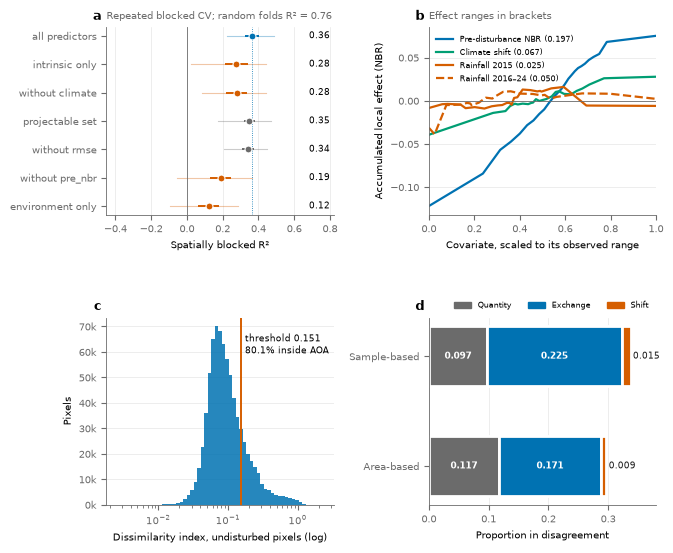

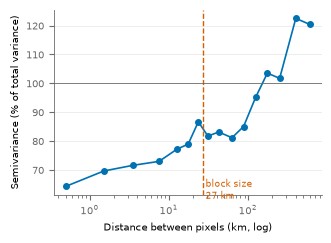

In [8]:
BLUE, ORANGE, GREEN, INK, MUTED, GRID = "#0072B2", "#D55E00", "#009E73", "#1a1a1a", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"font.size": 7.5, "axes.edgecolor": MUTED, "axes.linewidth": 0.6,
                     "xtick.color": MUTED, "ytick.color": MUTED, "savefig.dpi": 400,
                     "savefig.bbox": "tight"})
def tidy(ax, grid="x"):
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
    ax.grid(axis=grid, color=GRID, lw=0.5); ax.set_axisbelow(True)
def tag(ax, t): ax.text(-0.02, 1.04, t, transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right")

acc = json.load(open(TABDIR / "accuracy_summary.json"))["disagreement"]
fig = plt.figure(figsize=(7.09, 6.2)); gs = fig.add_gridspec(2, 2, hspace=0.55, wspace=0.42)

ax = fig.add_subplot(gs[0, 0]); S = OUT["cv"]["sets"]; order = list(SETS)
for yi, k in zip(np.arange(len(order))[::-1], order):
    col = BLUE if k == "all predictors" else (ORANGE if S[k]["delta"] < -0.03 else MUTED)
    ax.plot([S[k]["fold_min"], S[k]["fold_max"]], [yi, yi], color=col, lw=0.8, alpha=0.35)
    ax.errorbar(S[k]["r2_mean"], yi, xerr=1.96 * S[k]["r2_sd"], fmt="o", ms=5, color=col,
                mec="white", mew=0.8, elinewidth=1.4, zorder=3)
    ax.text(0.80, yi, f"{S[k]['r2_mean']:.2f}", va="center", ha="right", fontsize=6.5)
ax.axvline(base, color=BLUE, lw=0.6, ls=":"); ax.axvline(0, color=MUTED, lw=0.6)
ax.set_yticks(np.arange(len(order))[::-1], order); ax.set_xlim(-0.45, 0.82)
ax.set_xlabel("Spatially blocked R²")
ax.set_title(f"Repeated blocked CV; random folds R² = {OUT['cv']['r2_random']:.2f}", fontsize=7, color=MUTED, loc="left")
tidy(ax); tag(ax, "a")

ax = fig.add_subplot(gs[0, 1])
for k, lab, col, ls in [("pre_nbr", "Pre-disturbance NBR", BLUE, "-"), ("climate_shift", "Climate shift", GREEN, "-"),
                        ("rain_2015_mm", "Rainfall 2015", ORANGE, "-"), ("rain_recovery_mm", "Rainfall 2016–24", ORANGE, "--")]:
    if k not in ALE: continue
    xs, vs = np.array(ALE[k]["x"]), np.array(ALE[k]["ale"])
    ax.plot((xs - xs.min()) / (xs.max() - xs.min()), vs, color=col, lw=1.6, ls=ls, label=f"{lab} ({ALE[k]['range']:.3f})")
ax.axhline(0, color=MUTED, lw=0.6); ax.set_xlim(0, 1); ax.legend(frameon=False, fontsize=6, loc="upper left")
ax.set_xlabel("Covariate, scaled to its observed range"); ax.set_ylabel("Accumulated local effect (NBR)")
ax.set_title("Effect ranges in brackets", fontsize=7, color=MUTED, loc="left"); tidy(ax, "y"); tag(ax, "b")

ax = fig.add_subplot(gs[1, 0])
bins = np.logspace(np.log10(max(un.DI.min(), 1e-3)), np.log10(un.DI.max()), 60)
ax.hist(un.DI, bins=bins, color=BLUE, alpha=0.85, lw=0); ax.axvline(THRESH, color=ORANGE, lw=1.4)
ax.set_xscale("log"); ax.set_xlabel("Dissimilarity index, undisturbed pixels (log)"); ax.set_ylabel("Pixels")
ax.text(THRESH * 1.15, ax.get_ylim()[1] * 0.92, f"threshold {THRESH:.3f}\n{OUT['aoa']['pct_inside']:.1f}% inside AOA", fontsize=6.5, va="top")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v_, _: f"{v_/1000:.0f}k")); tidy(ax, "y"); tag(ax, "c")

ax = fig.add_subplot(gs[1, 1])
acc_all = json.load(open(TABDIR / "accuracy_summary.json"))
bars = [("Sample-based", acc_all.get("disagreement_sample")), ("Area-based", acc_all["disagreement"])]
bars = [(n_, b_) for n_, b_ in bars if b_]
for yi, (nm_, dd) in zip([1, 0][:len(bars)], bars):
    left = 0
    for lab, val, col in [("Quantity", dd["quantity"], MUTED), ("Exchange", dd["exchange"], BLUE), ("Shift", dd["shift"], ORANGE)]:
        ax.barh(yi, val, left=left, height=0.55, color=col, edgecolor="white", linewidth=2)
        if val > 0.03: ax.text(left + val / 2, yi, f"{val:.3f}", ha="center", va="center", color="white", fontsize=6.5, fontweight="bold")
        else: ax.text(left + val + 0.004, yi, f"{val:.3f}", ha="left", va="center", color=INK, fontsize=6.5)
        left += val
ax.set_yticks([1, 0][:len(bars)], [b_[0] for b_ in bars]); ax.set_xlim(0, 0.38)
ax.set_xlabel("Proportion in disagreement")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=MUTED, label="Quantity"), Patch(color=BLUE, label="Exchange"), Patch(color=ORANGE, label="Shift")],
          frameon=False, fontsize=6, loc="upper right", ncol=3, bbox_to_anchor=(1, 1.13))
tidy(ax); tag(ax, "d")
fig.savefig(FIGDIR / "fig14_statistical_robustness.png"); plt.show()

fig, ax = plt.subplots(figsize=(3.46, 2.4))
ax.plot(vg.mid_km, vg.pct_of_sill, "o-", color=BLUE, ms=4, lw=1.2)
ax.axvline(27, color=ORANGE, lw=1, ls="--"); ax.text(29, 60, "block size\n27 km", fontsize=6.5, color=ORANGE)
ax.axhline(100, color=MUTED, lw=0.6); ax.set_xscale("log")
ax.set_xlabel("Distance between pixels (km, log)"); ax.set_ylabel("Semivariance (% of total variance)")
tidy(ax, "y"); fig.savefig(FIGDIR / "figS1_variogram.png"); plt.show()

In [9]:
def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, list): return [clean(v) for v in o]
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return float(o)
    return o
json.dump(clean(OUT), open(TABDIR / "stats_robustness.json", "w"), indent=2)

R, cvs = OUT["resilience"], OUT["cv"]["sets"]
print("=" * 64); print("OUTPUT fo THESIS"); print("=" * 64)
print(f"Never recovered        {R['never_recovered_pct']['estimate']:.1f}% [{R['never_recovered_pct']['lo']:.1f}-{R['never_recovered_pct']['hi']:.1f}]")
print(f"Secondary decline      {R['secondary_decline_pct']['estimate']:.1f}% [{R['secondary_decline_pct']['lo']:.1f}-{R['secondary_decline_pct']['hi']:.1f}]")
print(f"Below threshold (adj)  {R['adj_below_threshold_pct']['estimate']:.1f}% [{R['adj_below_threshold_pct']['lo']:.1f}-{R['adj_below_threshold_pct']['hi']:.1f}]")
print(f"West - east recovery   {R['ew_diff']['estimate']:+.3f} [{R['ew_diff']['lo']:+.3f}, {R['ew_diff']['hi']:+.3f}]")
print(f"Blocked R2 (all)       {cvs['all predictors']['r2_mean']:.3f} +/- {cvs['all predictors']['r2_sd']:.3f}")
print(f"Random-fold R2         {OUT['cv']['r2_random']:.3f}  (inflation {OUT['cv']['inflation']:+.3f})")
print(f"Without climate        {cvs['without climate']['r2_mean']:.3f}")
print(f"Without pre_nbr        {cvs['without pre_nbr']['r2_mean']:.3f}")
if "rain_recovery_mm" in OUT["dutilleul"]:
    m_ = OUT["dutilleul"]["rain_recovery_mm"]
    print(f"Rain 2016-24 vs recov  r = {m_['r']:+.2f}, M_eff = {m_['M_eff']:.0f}, p = {m_['p_median']:.2f}")
print(f"AOA                    {OUT['aoa']['pct_inside']:.1f}% inside (real raster: {OUT['aoa_used_real_raster']})")
for r_ in OUT["aoa"]["table"]:
    print(f"   {r_['region']:<5}{r_['subset']:<12} vulnerable {r_['vulnerable_pct']:.1f}% ({r_['vulnerable_ha']:,.0f} ha)")
print("\nsaved: tables/stats_robustness.json, figures/fig14_statistical_robustness.png, figures/figS1_variogram.png")

OUTPUT for THESIS
Never recovered        26.7% [18.2-38.6]
Secondary decline      9.6% [7.4-11.9]
Below threshold (adj)  44.4% [33.4-58.5]
West - east recovery   -0.338 [-0.480, -0.192]
Blocked R2 (all)       0.365 +/- 0.020
Random-fold R2         0.759  (inflation +0.394)
Without climate        0.279
Without pre_nbr        0.189
Rain 2016-24 vs recov  r = +0.25, M_eff = 32, p = 0.19
AOA                    80.1% inside (real raster: True)
   east all pixels   vulnerable 6.4% (1,895 ha)
   east inside AOA   vulnerable 7.3% (1,728 ha)
   west all pixels   vulnerable 41.0% (14,688 ha)
   west inside AOA   vulnerable 46.6% (13,511 ha)

saved: tables/stats_robustness.json, figures/fig14_statistical_robustness.png, figures/figS1_variogram.png


In [14]:
"""
DIAGNOSTIC — why the dieback and undisturbed edge fractions disagree.
 
"""
 
import numpy as np
import pandas as pd
import rasterio
from scipy import ndimage
from scipy.spatial import cKDTree
from collections import Counter
 
print("=" * 70)
print("EDGE DIAGNOSTIC")
print("=" * 70)
print("raster being used:", RASTER)
 
#  1. what is actually in the class map 
cnt = Counter()
with rasterio.open(RASTER) as src:
    tr, H, W = src.transform, src.height, src.width
    res_deg = abs(tr.a)
    res_m = res_deg * 111320
    for _, win in src.block_windows(1):
        a = src.read(1, window=win)
        v, n = np.unique(a, return_counts=True)
        for vv, nn in zip(v, n):
            cnt[int(vv)] += int(nn)
 
print(f"\n1. RASTER CONTENTS   {H:,} x {W:,} cells at ~{res_m:.1f} m")
for v in sorted(cnt):
    if v > 0:
        print(f"     class {v}: {cnt[v]:>12,} cells")
n_mang = sum(n for v, n in cnt.items() if v > 0)
print(f"     total mangrove (class > 0): {n_mang:,} cells")
print(f"     class 2 count {cnt.get(2, 0):,}  vs dieback rows in d: {len(d):,}"
      f"   {'MATCH' if cnt.get(2, 0) == len(d) else '*** MISMATCH ***'}")
 
# 2. rebuild the boundary set from that same raster 
mang, bnd = [], []
with rasterio.open(RASTER) as src:
    for _, win in src.block_windows(1):
        r0, c0 = int(win.row_off), int(win.col_off)
        a = src.read(1, window=win)
        if not a.any():
            continue
        m = a > 0
        e = m & ~ndimage.binary_erosion(m, np.ones((3, 3), bool))
        for mask, store in ((m, mang), (e, bnd)):
            r, c = np.nonzero(mask)
            if len(r):
                store.append(np.column_stack([r + r0, c + c0]).astype(np.int32))
mang = np.vstack(mang)
bnd = np.vstack(bnd)
base = len(bnd) / len(mang)
print(f"\n2. BOUNDARY SET      {len(bnd):,} boundary cells of {len(mang):,} mangrove cells")
print(f"     BASE RATE: {base:.1%} of all mangrove cells are boundary cells.")
print(f"     Any population with a higher share is edge-enriched; at or below")
print(f"     this value it is not distinguishable from randomly placed cells.")
 
LAT = float(np.nanmedian(d.latitude))
MX = res_deg * 111320 * np.cos(np.radians(LAT))
MY = res_deg * 110540
to_m = lambda rc: np.column_stack([rc[:, 1] * MX, rc[:, 0] * MY])
tree = cKDTree(to_m(bnd))
 
 
def edge_stats(lon, lat):
    rr, cc = rasterio.transform.rowcol(tr, np.asarray(lon), np.asarray(lat))
    rr = np.clip(np.asarray(rr), 0, H - 1)
    cc = np.clip(np.asarray(cc), 0, W - 1)
    return tree.query(to_m(np.column_stack([rr, cc])), k=1)[0]
 
 
# 3. do the stored dieback distances match a fresh computation? 
fresh_d = edge_stats(d.longitude.values, d.latitude.values)
stored_d = d["dist_to_edge"].values
 
print(f"\n3. DIEBACK PIXELS    n = {len(d):,}")
print(f"     recomputed now : on edge {(fresh_d == 0).mean():6.1%}"
      f"   within 1 px {(fresh_d <= res_m).mean():6.1%}"
      f"   median {np.median(fresh_d):7.1f} m")
print(f"     stored in CSV  : on edge {(stored_d == 0).mean():6.1%}"
      f"   within 1 px {(stored_d <= res_m).mean():6.1%}"
      f"   median {np.median(stored_d):7.1f} m")
agree = np.allclose(fresh_d, stored_d, atol=1.0)
print(f"     VERDICT: {'the stored column AGREES with this raster' if agree else '*** the stored column DOES NOT MATCH this raster ***'}")
if not agree:
    same = (np.abs(fresh_d - stored_d) <= 1.0).mean()
    print(f"     only {same:.1%} of pixels agree to within 1 m")
 
#  4. the grid-alignment check notebook 03 makes 
with rasterio.open(RASTER) as src:
    hit = np.array([v[0] for v in src.sample(
        np.column_stack([d.longitude.values[:5000], d.latitude.values[:5000]]))])
print(f"\n4. GRID ALIGNMENT    {(hit == 2).mean():.1%} of the first 5,000 dieback"
      f" pixels land on a class-2 cell")

 
# 5. the comparison 
fresh_u = un["dist_to_edge"].values
print(f"\n5. THE COMPARISON ")
print(f"     {'population':<22}{'n':>10}{'on edge':>10}{'enrichment':>12}{'median':>10}")
for nm_, s_, n_ in (("all mangrove (base)", None, len(mang)),
                    ("undisturbed", fresh_u, len(un)),
                    ("2015-16 dieback", fresh_d, len(d))):
    if s_ is None:
        print(f"     {nm_:<22}{n_:>10,}{base:>10.1%}{1.0:>11.1f}x{'-':>10}")
    else:
        f_ = (s_ == 0).mean()
        print(f"     {nm_:<22}{n_:>10,}{f_:>10.1%}{f_/base:>11.1f}x"
              f"{np.median(s_):>9.1f}m")
print("\n" + "=" * 70)


EDGE DIAGNOSTIC
raster being used: C:\mangrove-resilience\data\rasters\classmap_fullcoast_30m.tif

1. RASTER CONTENTS   14,944 x 24,120 cells at ~30.0 m
     class 1:      765,143 cells
     class 2:       29,453 cells
     class 3:      126,428 cells
     total mangrove (class > 0): 921,024 cells
     class 2 count 29,453  vs dieback rows in d: 29,453   MATCH

2. BOUNDARY SET      457,881 boundary cells of 921,024 mangrove cells
     BASE RATE: 49.7% of all mangrove cells are boundary cells.
     Any population with a higher share is edge-enriched; at or below
     this value it is not distinguishable from randomly placed cells.

3. DIEBACK PIXELS    n = 29,453
     recomputed now : on edge  13.0%   within 1 px  25.7%   median    89.4 m
     stored in CSV  : on edge  13.0%   within 1 px  25.7%   median    89.4 m
     VERDICT: the stored column AGREES with this raster

4. GRID ALIGNMENT    100.0% of the first 5,000 dieback pixels land on a class-2 cell

5. THE COMPARISON 
     populati

In [13]:
"""
Completes the selection-effect evidence: are the dieback points the map MISSED
also closer to a stand boundary than the ones it CAUGHT?
 
"""
 
import numpy as np
import pandas as pd
import rasterio
from scipy import stats
 
full = pd.read_csv(DATA / "sample400_full.csv")
blind_name = next(n for n in ("sample400_blind.csv", "s400blind.csv")
                  if (DATA / n).exists())
blind = pd.read_csv(DATA / blind_name)
 
PRE = [f"nbr_{y}" for y in range(2011, 2015)]
s = full[["point_id", "lon", "lat", "map_class"] + PRE].merge(
    blind[["point_id", "ref_class"]], on="point_id")
s["canopy"] = s[PRE].mean(axis=1) / 0.80
s["req_m"] = 0.1875 / s.canopy.clip(lower=1e-6)
 
# distance to the nearest stand boundary
rr, cc = rasterio.transform.rowcol(tr, s.lon.values, s.lat.values)
P = to_m(np.column_stack([np.clip(np.asarray(rr), 0, H - 1),
                          np.clip(np.asarray(cc), 0, W - 1)]))
s["edge_m"] = tree.query(P, k=1)[0]
 
det = s[(s.map_class == 2) & (s.ref_class == 2)]      # true detections
mis = s[(s.map_class != 2) & (s.ref_class == 2)]      # omissions
 
print("=" * 74)
print("REFERENCE DIEBACK: what the map caught vs what it missed")
print("=" * 74)
print(f"{'':<22}{'n':>4}{'canopy':>9}{'req. mortality':>16}{'on edge':>10}{'median edge':>13}")
for nm, g in (("detected by map", det), ("MISSED by map", mis)):
    print(f"{nm:<22}{len(g):>4}{g.canopy.median():>9.2f}{g.req_m.median():>15.1%}"
          f"{(g.edge_m == 0).mean():>10.1%}{g.edge_m.median():>12.1f}m")
print(f"{'base rate, all mangrove':<22}{'':>4}{'':>9}{'':>16}{base:>10.1%}")
 
print("\nTests (one-sided, as the mixture model predicts the direction):")
u, p = stats.mannwhitneyu(det.canopy, mis.canopy, alternative="greater")
print(f"  canopy: detected > missed          U={u:>6.0f}  P={p:.4f}"
      f"   {'SUPPORTS the mechanism' if p < 0.05 else 'not significant'}")
u2, p2 = stats.mannwhitneyu(mis.edge_m, det.edge_m, alternative="less")
print(f"  edge  : missed closer to boundary  U={u2:>6.0f}  P={p2:.4f}"
      f"   {'SUPPORTS the mechanism' if p2 < 0.05 else 'not significant'}")
 


REFERENCE DIEBACK: what the map caught vs what it missed
                         n   canopy  req. mortality   on edge  median edge
detected by map        117     0.86          21.8%     22.2%        89.4m
MISSED by map           19     0.74          25.5%     36.8%        29.8m
base rate, all mangrove                                  49.7%

Tests (one-sided, as the mixture model predicts the direction):
  canopy: detected > missed          U=  1767  P=0.0000   SUPPORTS the mechanism
  edge  : missed closer to boundary  U=   720  P=0.0067   SUPPORTS the mechanism


In [12]:
s.to_csv(TABDIR / "reference_point_geometry.csv", index=False)
print("saved", TABDIR / "reference_point_geometry.csv")

saved C:\mangrove-resilience\tables\reference_point_geometry.csv
